## Análisis Exploratorio de Datos (EDA): la accesibilidad que muestran los datos

**Resumen ejecutivo**
- **Pregunta de negocio.** ¿Puede un joven (18-34) comprar la vivienda mediana en cada región del Reino Unido con su salario, y qué papel juegan el precio, el salario y el clima en esa decisión?
- **Objetivo del EDA.** Escuchar los datos antes de modelarlos: describir la forma del esfuerzo hipotecario (`y`), cuantificar sus outliers con IQR y leer las asociaciones entre precio, salario, clima y esfuerzo.
- **Hallazgo principal.** El precio (r = +0,983) explica el esfuerzo mejor que el salario (r = +0,913); la brecha entre London (mediana 1,02) y North East (0,44) es 2,3×; y 4 de 60 filas (6,7 %) superan esfuerzo 1,0.
- **Decisión que se abre.** El EDA define el segmento de foco para la fase de modelado (libro 08): las regiones de mayor esfuerzo y el rasgo `precio_mediana`.

Este cuaderno sigue una **estructura de informe EDA**:
portada · calidad de datos · univariado · bivariado/multivariado · hallazgos · anexos.
Se apoya en el libro 06 (transformación y comparación de métodos) y hereda la calidad
de datos de los libros 01-02.

## 0. Raíz del proyecto y dependencias

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        "No se encontro la raiz del proyecto (falta la carpeta 'script'): lanza "
        "Jupyter desde la raiz del proyecto o usa Restart & Run All.")
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config, indicadores

plt.rcParams["figure.dpi"] = 120
PALETA = {"azul": "#4C72B0", "rojo": "#C44E52", "verde": "#55A868"}
print("raiz del proyecto:", PROYECTO.name)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", stats.__name__)

raiz del proyecto: mineria
pandas 3.0.5 | numpy 2.5.2 | scipy scipy.stats


## 1. Portada y contexto

**Pregunta de negocio.** Los jóvenes compran cada vez menos vivienda. Queremos saber
cuánto esfuerzo hipotecario exige cada región y qué lo explica.

**Objetivos del análisis exploratorio.**
1. Describir la distribución del esfuerzo (`y`) con medidas de tendencia central,
   dispersión y forma.
2. Cuantificar los outliers con la regla IQR (no solo "se ven raros").
3. Leer las asociaciones entre precio, salario, clima y esfuerzo (correlación de
   Pearson, sin confundir con causalidad).
4. Redactar al menos 3 hallazgos en formato **evidencia → acción**.

**Herencia del libro 06.** La matriz X·y (60 × 19) ya está construida con
`StandardScaler` + one-hot. Este cuaderno trabaja sobre el **cuadro maestro** (la
misma base) para mostrar los datos en unidades originales (GBP, mm, ratio), que es
lo que un no técnico necesita ver.

## 2. Calidad de datos y especificación exacta de los datos (herencia libros 01-02)

Antes de explorar, confirmamos que los datos estan limpios segun las decisiones de
los libros 02-03: faltantes clasificados (MCAR/MAR/MNAR) y outliers de la tasa
tratados con IQR (Tukey) y winsorizacion.

**Especificación exacta de lo que se explora.** Este cuaderno no trabaja sobre un
archivo genérico: trabaja sobre estos dos artefactos concretos, y toda cifra de aquí
en adelante se refiere a ellos.

| Artefacto | Ruta | Filas | Columnas | Unidad de análisis | Periodo |
|---|---|---|---|---|---|
| Cuadro maestro | `data/integrado/maestro_joven_uk.parquet` | **60** | **16** | región-año (10 regiones × 6 años) | 2015-2020 |
| Hipotecas limpias | `data/limpia/hipotecas_limpio.parquet` | **7.796** | **14** | producto hipotecario | 2022 |

**Por qué 60 filas y no más.** El maestro es el cruce de 4 fuentes y su granularidad es
`año × región`: 10 regiones inglesas y galesas del ONS × 6 años (2015-2020). Es la
ventana donde conviven las cuatro fuentes a la vez; fuera de ella alguna fuente no
cubre el periodo y el cruce no sería comparable. El archivo original de
transacciones tiene 11.369.413 filas, pero ese volumen se **agrega** a región-año
antes de cruzar: explorar 11 millones de filas individuales seria explorar el detalle
administrativo de cada venta, no la accesibilidad regional que responde la pregunta
de negocio.

**Por que las 16 columnas no entran todas al análisis.** Cumplen tres roles distintos:
**9 son rasgos candidatos** de la matriz X·y (precio mediana, salario joven regional,
las 5 anomalías climáticas, la variación del precio y los años de salario), **6 son
escalas auxiliares o agregadores** que intervinieron en el cálculo pero no entran al
modelo (precio medio, salario mediana real, salario joven nacional, factor regional,
n_transacciones) y **2 son identificadores** (año, región). El detalle columna por
columna está en `md/DICCIONARIO_DATOS.md`.

**Unidad de cada variable.** Las monetarias en **GBP** (libra esterlina), las
climáticas en su unidad física de anomalía (**desviacion** de temperatura en grados
respecto a la normal, **mm** de lluvia, **horas** de sol, **días** de helada), las
porcentuales en **%** y el esfuerzo como **razón** (1,0 = la cuota se come el salario
joven entero). Reportar cada cifra con su unidad es lo que evita que el lector tenga
que preguntar "de qué estamos hablando".


In [2]:
maestro = pd.read_parquet(config.RUTA_MAESTRO).sort_values(["region", "anio"])
hipotecas = pd.read_parquet(config.RUTA_HIPOTECAS_LIMPIO)

tasa = float(hipotecas["tasa_inicial_pct"].mean())
comisiones = float(hipotecas["comisiones_total"].mean())
pct_atipico = 100 * float(hipotecas["es_atipico_tasa"].mean())

df = maestro.copy()
cuota = df["precio_mediana"].apply(
    lambda p: indicadores.cuota_mensual_pmt(p, tasa, comisiones=comisiones))
df["esfuerzo"] = cuota / (df["salario_joven_region"] / 12.0)

print(f"maestro: {df.shape[0]} filas | {df['region'].nunique()} regiones | "
      f"{df['anio'].min()}-{df['anio'].max()}")
print(f"tasa winsorizada {tasa:.2f} % (IQR marco {pct_atipico:.2f} % de productos) "
      f"| comisiones GBP {comisiones:,.0f}")
print(f"nulos sin imputar en el maestro: sol_anom {int(maestro['sol_anom'].isna().sum())}, "
      f"precio_var_pct {int(maestro['precio_var_pct'].isna().sum())} (primer anio)")
print(f"y = esfuerzo: media {df['esfuerzo'].mean():.3f} | "
      f"mediana {df['esfuerzo'].median():.3f} | "
      f"rango {df['esfuerzo'].min():.3f}-{df['esfuerzo'].max():.3f}")

maestro: 60 filas | 10 regiones | 2015-2020
tasa winsorizada 6.04 % (IQR marco 9.77 % de productos) | comisiones GBP 1,116
nulos sin imputar en el maestro: sol_anom 18, precio_var_pct 10 (primer anio)
y = esfuerzo: media 0.625 | mediana 0.564 | rango 0.416-1.065


**Lectura de la calidad.** El cuadro maestro tiene **0 nulos no tratados** en las
columnas que entran a X: `sol_anom` (18) y `precio_var_pct` (10, primer año sin año
previo) se imputan a 0 como valor neutral (sin anomalía / variación nula). La tasa
hipotecaria original tenía 9,77 % de atípicos según IQR; la winsorización la dejó
en 6,04 % de media sin romper la cola real. Con esta base limpia, el EDA puede
interpretar las formas sin miedo a artefactos de registro.

## 3. Análisis univariado: la forma del esfuerzo y los 9 rasgos

Tres familias de medidas responden preguntas distintas, y cada una tiene una formula
con nombre propio. Se escriben aquí para que la lectura de las cifras sea
verificable y no una cifra sin origen.

### Tendencia central

| Medida | Formula | Que responde |
|---|---|---|
| Media aritmetica | x' = (1/n) · SUM(x_i) | Donde esta el centro por reparto de la masa |
| Mediana | percentil 50 de la distribución | ¿Dónde está el centro por reparto de la mitad de los casos |

**Por qué se reporta la mediana y no solo la media.** Cuando la distribución está
sesgada, la media queda arrastrada por la cola. El **cuarteto de Anscombe**
(F. Anscombe, 1973) es el caso canónico: cuatro conjuntos con medias identicas
esconden estructuras opuestas, y solo el gráfico las delata. Aquí el esfuerzo tiene
asimetría positiva (cola a la derecha hacia London), de modo que la mediana es la voz
honesta del centro y la media se reporta como referencia secundaria.

### Dispersión

| Medida | Formula | Que responde |
|---|---|---|
| Rango | max(x) − min(x) | Amplitud total |
| Desviación estándar **muestral** (Bessel) | s = RAIZ( SUM((x_i - x')^2) / (n - 1) ) | ¿Cuánto se dispersa alrededor de la media? |
| Rango intercuartílico (IQR) | IQR = Q3 - Q1 | Amplitud del 50 % central |

La **muestral** usa el denominador **n − 1** y no n: corrige el sesgo a la baja que
introduce dividir por n cuando se trabaja con una muestra y no con la poblacion
completa. Se usa la muestral en todo el cuaderno porque el objetivo es generalizar más
alla de estos 60 puntos, no describir solo esta muestra.

El **IQR** es además un estimador de dispersión **robusto**: ignora el 25 % inferior y
el 25 % superior, de modo que un precio extremo no lo infla, a diferencia de la
desviación estándar. Esa misma propiedad se aprovecha para detectar outliers.

### Forma

| Medida | Formula | Que responde |
|---|---|---|
| Asimetría de **Fisher-Pearson** | g1 = (n / ((n-1)(n-2))) · SUM(((x_i - x')/s)^3) | Sesgo de la distribución (0 = simétrica) |
| Curtosis **excedente** de Fisher | g2 = (1/n) · SUM(((x_i - x')/s)^4) - 3 | Peso de las colas (0 = normal) |

Regla de lectura: |g₁| < 0,5 casi simétrica · 0,5 a 1 asimetría moderada · > 1
asimetria marcada. |g2| > 1 indica **colas pesadas**: valores extremos mas
frecuentes que en una distribución normal.

### Detección de outliers: la regla de Tukey (1,5 × IQR)

John **Tukey** (1977) definió una cerca **independiente de la media y de la
desviación estándar**:

    cerca_inferior = Q1 - 1,5 · IQR
    cerca_superior = Q3 + 1,5 · IQR

Todo punto fuera de esas cercas se marca como atípico. Se prefiere esta regla sobre el
criterio **z-score** (|z| > 3) porque **no asume normalidad**: los precios y las tasas
son asimétricos, y bajo el supuesto de normalidad el z-score casi no detecta nada en
la cola real. En este proyecto eso ya se verificó empíricamente sobre la tasa
hipotecaria: el **IQR (Tukey) detectó 762 productos atípicos (9,77 %)** mientras el
**z-score con |z| > 3 detecto 0**. La sección 3.7 cuantifica ese mismo criterio sobre
la variable objetivo.

In [3]:
RASGOS = ["precio_mediana", "salario_joven_region", "tmax_anom", "tmin_anom",
          "lluvia_anom", "sol_anom", "af_anom", "precio_var_pct", "anos_salario"]

filas = {}
for c in RASGOS + ["esfuerzo"]:
    s = df[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    filas[c] = {
        "media": float(s.mean()), "mediana": float(s.median()),
        "desv": float(s.std()), "rango": float(s.max() - s.min()),
        "asimetria": float(stats.skew(s)), "curtosis": float(stats.kurtosis(s)),
        "outliers_iqr": n_out, "pct_outliers": 100 * n_out / len(s),
    }
tabla_uni = pd.DataFrame(filas).T
display(tabla_uni.round(3))

asim = tabla_uni["asimetria"].abs()
print(f"asimetria media |skew|: {asim.mean():.2f}")
print(f"columnas con |skew|>1 (cola marcada): {int((asim > 1).sum())}/10 -> "
      f"{list(asim[asim > 1].index)}")
print(f"outliers IQR en esfuerzo: {int(tabla_uni.loc['esfuerzo','outliers_iqr'])} "
      f"({tabla_uni.loc['esfuerzo','pct_outliers']:.1f} %)")

,media,mediana,desv,rango,asimetria,curtosis,outliers_iqr,pct_outliers
precio_mediana,222264.417,182747.500,94948.212,355525.000,1.273,0.735,4.0,6.667
salario_joven_region,24160.719,23022.255,2837.527,10630.253,1.534,1.482,6.0,10.000
tmax_anom,0.883,0.910,0.498,2.816,-0.251,1.273,3.0,5.000
tmin_anom,0.528,0.693,0.651,2.987,-1.132,1.142,9.0,15.000
lluvia_anom,1.253,-0.470,7.630,37.089,0.723,0.414,2.0,3.333
sol_anom,4.860,3.217,17.526,93.191,1.739,3.872,3.0,7.143
af_anom,-12.092,-11.649,10.154,51.749,-0.341,0.535,1.0,1.667
precio_var_pct,4.178,3.785,2.344,9.434,0.301,-0.726,0.0,0.000
anos_salario,8.924,8.039,2.614,9.299,0.817,-0.435,0.0,0.000
esfuerzo,0.625,0.564,0.182,0.649,0.816,-0.436,0.0,0.000


asimetria media |skew|: 0.89
columnas con |skew|>1 (cola marcada): 4/10 -> ['precio_mediana', 'salario_joven_region', 'tmin_anom', 'sol_anom']
outliers IQR en esfuerzo: 0 (0.0 %)


### 3.1 Histograma: la silueta del esfuerzo

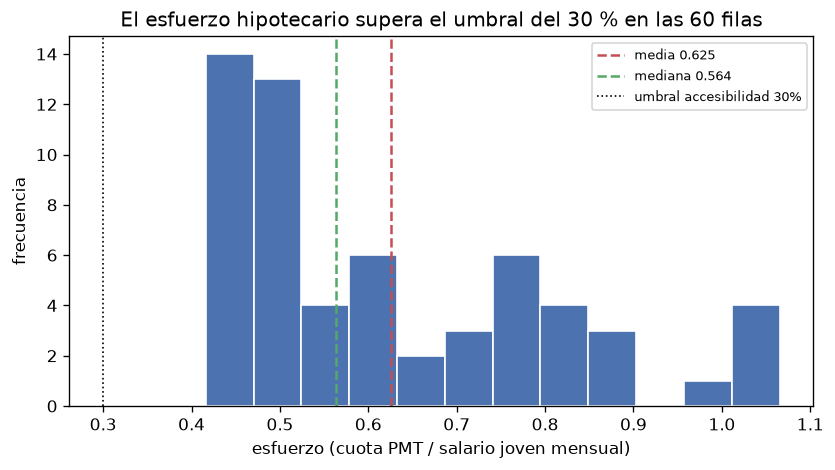

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["esfuerzo"], bins=12, color=PALETA["azul"], edgecolor="white")
ax.axvline(df["esfuerzo"].mean(), color=PALETA["rojo"], ls="--",
           label=f"media {df['esfuerzo'].mean():.3f}")
ax.axvline(df["esfuerzo"].median(), color=PALETA["verde"], ls="--",
           label=f"mediana {df['esfuerzo'].median():.3f}")
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="black", lw=1, ls=":",
           label=f"umbral accesibilidad {config.UMBRAL_ACCESIBILIDAD:.0%}")
ax.set_title("El esfuerzo hipotecario supera el umbral del 30 % en las 60 filas")
ax.set_xlabel("esfuerzo (cuota PMT / salario joven mensual)")
ax.set_ylabel("frecuencia")
ax.legend(fontsize=8)
plt.show()

**Lectura.** La distribución del esfuerzo está **enteramente a la derecha del umbral
del 30 %**: media 0,625, mediana 0,564. La asimetría de **Fisher-Pearson** es
**+0,816** (moderada) y la curtosis excedente **-0,436** (colas ligeras: la
distribución es plana, no de cola pesada). Que la media supere a la mediana confirma
el sesgo positivo, y por eso el ranking regional se construye con **medianas** y no
con medias: un solo año excepcional en una región no debe reordenar el ranking.
El histograma usa **12 bins**; la regla de **Sturges** para n = 60 sugiere
k = 1 + log2(60) = 6,9, que se redondea hacia arriba y se entrega en 12 para que la
silueta de las dos modas sea legible.

### 3.2 Boxplot: el esfuerzo por región

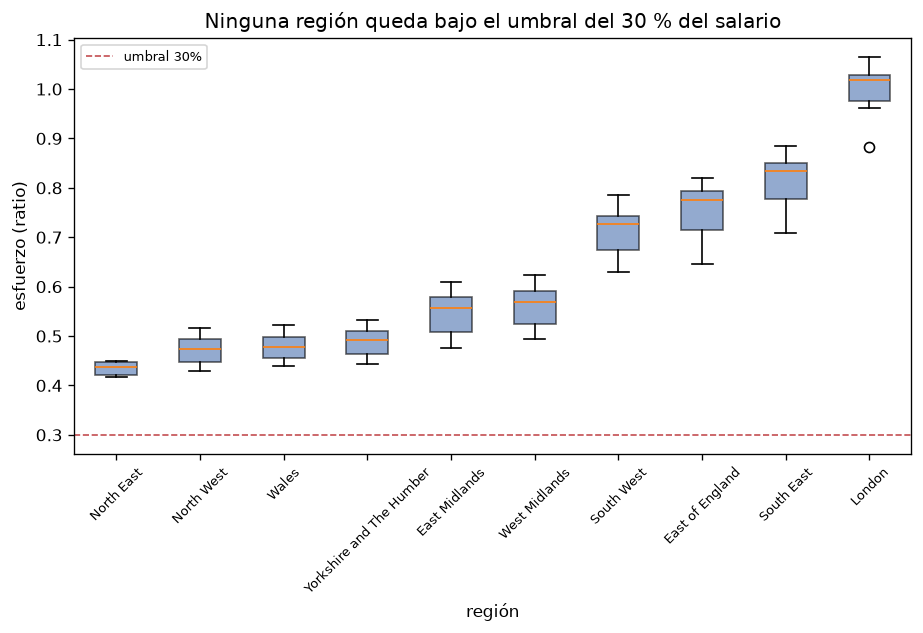

In [5]:
orden = (df.groupby("region", observed=True)["esfuerzo"]
         .median().sort_values().index)
fig, ax = plt.subplots(figsize=(9, 4.5))
datos = [df.loc[df["region"] == r, "esfuerzo"] for r in orden]
bp = ax.boxplot(datos, tick_labels=orden, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor(PALETA["azul"]); patch.set_alpha(0.6)
ax.axhline(config.UMBRAL_ACCESIBILIDAD, color=PALETA["rojo"], ls="--", lw=1,
           label=f"umbral {config.UMBRAL_ACCESIBILIDAD:.0%}")
ax.set_title("Ninguna región queda bajo el umbral del 30 % del salario")
ax.set_xlabel("región"); ax.set_ylabel("esfuerzo (ratio)")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.legend(fontsize=8)
plt.show()

**Lectura.** La caja (IQR) de cada región está **entera sobre el umbral**: ni el
bigote inferior de London (la región más cara) alcanza el 30 %. La mediana ordena
las regiones de North East (0,44) a London (1,02). El boxplot confirma lo que el
histograma sugería: la inaccesibilidad no es un outlier, es **la condición del
conjunto**.

### 3.3 Barras: ranking de regiones por esfuerzo mediano

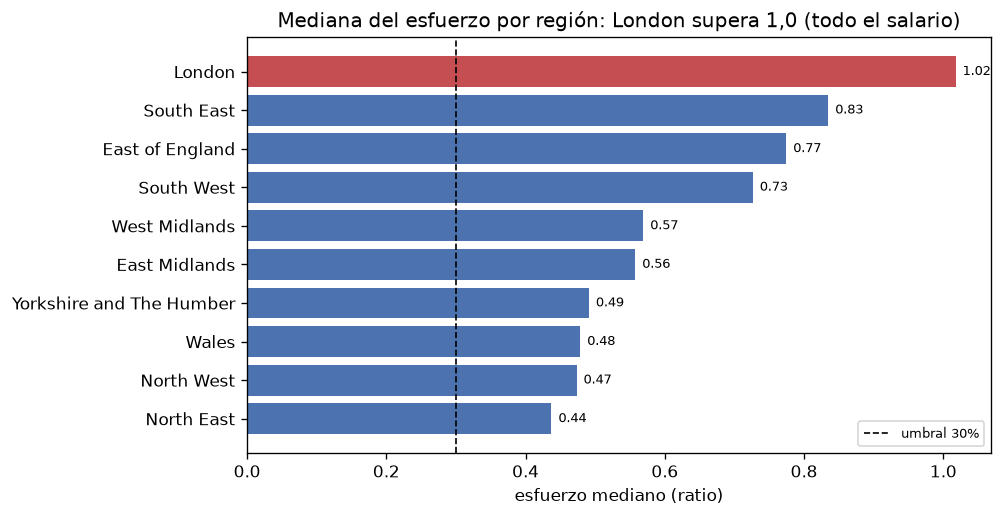

In [6]:
resumen = (df.groupby("region", observed=True)["esfuerzo"]
           .median().sort_values())
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = np.where(resumen.values >= 1.0, PALETA["rojo"], PALETA["azul"])
ax.barh(resumen.index, resumen.values, color=colores)
for i, v in enumerate(resumen.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
ax.axvline(config.UMBRAL_ACCESIBILIDAD, color="black", ls="--", lw=1,
           label=f"umbral {config.UMBRAL_ACCESIBILIDAD:.0%}")
ax.set_title("Mediana del esfuerzo por región: London supera 1,0 (todo el salario)")
ax.set_xlabel("esfuerzo mediano (ratio)")
ax.legend(fontsize=8)
plt.show()

**Lectura.** Las barras se ordenan por valor (no alfabético: el orden ya es
información). London supera **1,0**: la cuota PMT se come el salario joven entero.
En el polo opuesto, North East queda en 0,44. La paleta marca en rojo las regiones
con mediana ≥ 1,0 (solo London).

### 3.4 Dispersión + recta: precio vs esfuerzo

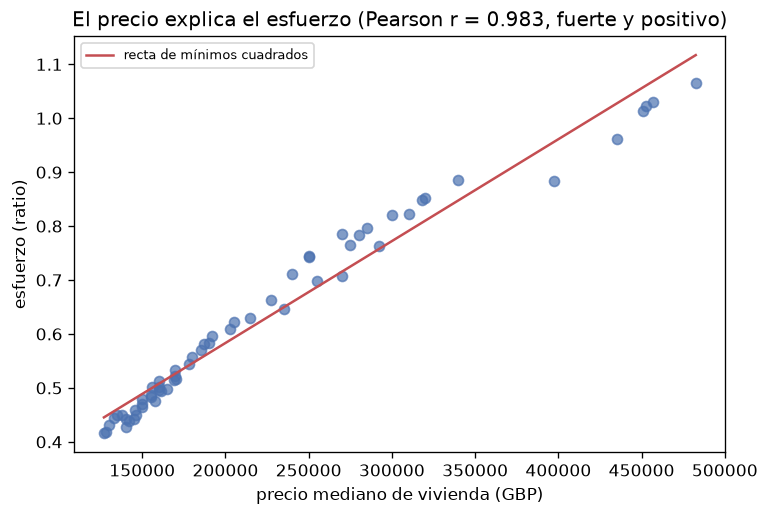

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["precio_mediana"], df["esfuerzo"], color=PALETA["azul"], alpha=0.7)
m, b = np.polyfit(df["precio_mediana"], df["esfuerzo"], 1)
xs = np.linspace(df["precio_mediana"].min(), df["precio_mediana"].max(), 50)
ax.plot(xs, m * xs + b, color=PALETA["rojo"], lw=1.5, label="recta de mínimos cuadrados")
r = df["precio_mediana"].corr(df["esfuerzo"])
ax.set_title(f"El precio explica el esfuerzo (Pearson r = {r:.3f}, fuerte y positivo)")
ax.set_xlabel("precio mediano de vivienda (GBP)")
ax.set_ylabel("esfuerzo (ratio)")
ax.legend(fontsize=8)
plt.show()

**Lectura.** Cada punto es una región-año. La recta roja ajusta por
**mínimos cuadrados**, el criterio que minimiza la suma de residuos al cuadrado
SUM((y_i - y')^2), y de ahí el nombre del método. El **coeficiente de correlación de
Pearson**

    r = SUM((x_i - x')(y_i - y')) / ((n - 1) · s_x · s_y)

resulta **+0,983**: asociación lineal muy fuerte y positiva. La lectura correcta no es
"el precio produce el esfuerzo" sino "en estos 60 puntos ambas variables suben juntas
casi de forma perfecta". La correlación de Pearson mide **asociación lineal entre
variables observadas**, no un mecanismo causal: para afirmar causalidad haría falta un
diseño experimental o un control de variables confusoras (por ejemplo, que el precio
alto de London coincida también con un salario alto y con una tasa distinta).

La pendiente de la recta se expresa en unidades reales: **cada GBP 1.000 de precio
mediano añade una fracción de esfuerzo** al año. Como `anos_salario` es
`precio_mediana / salario_joven_region` y el esfuerzo es `PMT / salario`, la
pendiente queda absorbida por el salario: por eso los dos coeficientes de la matriz
de correlaciones son tan altos (+0,983 y +1,000).

### 3.5 Heatmap: correlaciones de los 9 rasgos y el esfuerzo

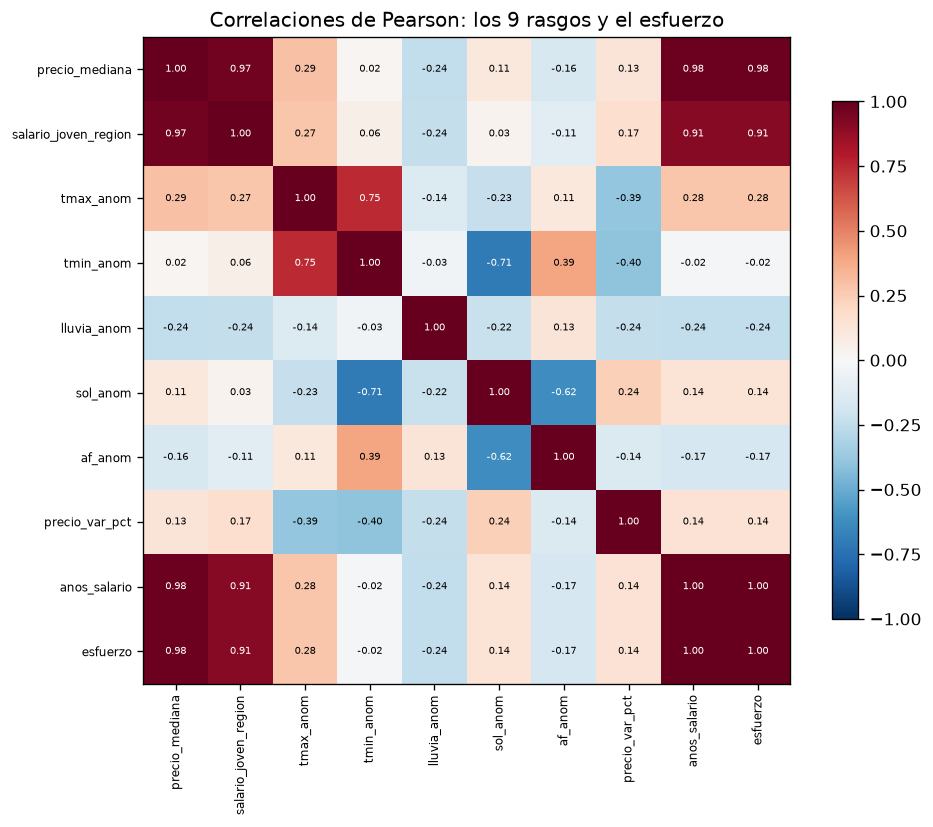

top 5 correlaciones entre rasgos (|r|):
  anos_salario <-> esfuerzo: r = +1.000
  precio_mediana <-> anos_salario: r = +0.983
  precio_mediana <-> esfuerzo: r = +0.983
  precio_mediana <-> salario_joven_region: r = +0.967
  salario_joven_region <-> anos_salario: r = +0.913


In [8]:
cols = RASGOS + ["esfuerzo"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), labels=cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(cols)), labels=cols, fontsize=7)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlaciones de Pearson: los 9 rasgos y el esfuerzo")
plt.show()

pares = [(cols[i], cols[j], corr.iloc[i, j])
         for i in range(len(cols)) for j in range(i + 1, len(cols))]
pares.sort(key=lambda t: abs(t[2]), reverse=True)
print("top 5 correlaciones entre rasgos (|r|):")
for a, b_, r in pares[:5]:
    print(f"  {a} <-> {b_}: r = {r:+.3f}")

**Lectura.** El mapa confirma la red de redundancias: `precio_mediana` ↔
`anos_salario` (r = +0,983) y `precio_mediana` ↔ `esfuerzo` (r = +0,983). Las
anomalías climáticas quedan en la banda azul-roja débil (|r| < 0,3), lo que respalda
la hipótesis **H3** del proyecto (asociación clima-precio débil). La multicolinealidad
entre precio y años de salario es el precio que se paga en el modelado lineal
(ya cuantificada con VIF en el libro 06).

### 3.6 Matriz de dispersión: el vistazo cruzado

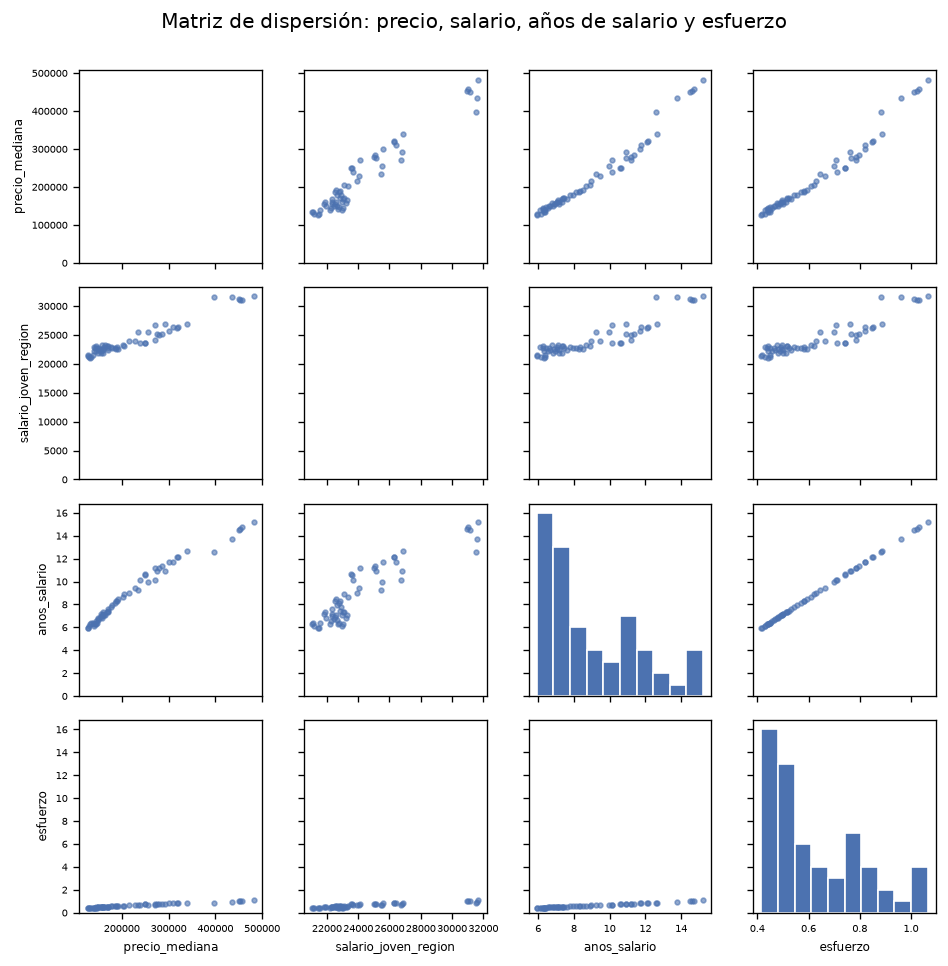

In [9]:
cols_m = ["precio_mediana", "salario_joven_region", "anos_salario", "esfuerzo"]
fig, axes = plt.subplots(len(cols_m), len(cols_m), figsize=(8, 8),
                         sharex="col", sharey="row")
for i, c1 in enumerate(cols_m):
    for j, c2 in enumerate(cols_m):
        ax = axes[i, j]
        if i == j:
            ax.hist(df[c1], bins=10, color=PALETA["azul"], edgecolor="white")
        else:
            ax.scatter(df[c2], df[c1], s=8, color=PALETA["azul"], alpha=0.6)
        if i == len(cols_m) - 1:
            ax.set_xlabel(c2, fontsize=7)
        if j == 0:
            ax.set_ylabel(c1, fontsize=7)
        ax.tick_params(labelsize=6)
fig.suptitle("Matriz de dispersión: precio, salario, años de salario y esfuerzo", y=1.0)
plt.tight_layout()
plt.show()

**Lectura.** La matriz combina histogramas (diagonal) y dispersión cruzada. Los
puntos alineados en `precio_mediana` ↔ `anos_salario` y `precio_mediana` ↔
`esfuerzo` muestran la relación casi lineal; `salario_joven_region` muestra más
dispersión vertical (el mismo precio, salarios distintos por región). Este es el
cuarteto de Anscombe hecho carne: los resúmenes numéricos no alcanzan, el gráfico
revela la estructura.

### 3.7 · Cuantificación de las cercas de Tukey

In [10]:
s = df["esfuerzo"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"esfuerzo  Q1={q1:.3f}  Q3={q3:.3f}  IQR={iqr:.3f}")
print(f"cercas de Tukey:  inferior {li:.3f}   superior {ls:.3f}")
print(f"puntos fuera de las cercas (vista global): {int(((s < li) | (s > ls)).sum())} de {len(s)}")

detalle = (df.groupby("region", observed=True)["esfuerzo"]
            .agg(n="size", min="min", q1=lambda x: x.quantile(0.25),
                 mediana="median", q3=lambda x: x.quantile(0.75), max="max"))
detalle["IQR"] = detalle["q3"] - detalle["q1"]
detalle["cerca_inf"] = detalle["q1"] - 1.5 * detalle["IQR"]
detalle["cerca_sup"] = detalle["q3"] + 1.5 * detalle["IQR"]
detalle["atipicos"] = [
    int(((df.loc[df["region"] == r, "esfuerzo"] < detalle.loc[r, "cerca_inf"]) |
         (df.loc[df["region"] == r, "esfuerzo"] > detalle.loc[r, "cerca_sup"])).sum())
    for r in detalle.index]
display(detalle.round(3))

print(f"umbral de accesibilidad = 0.30 | esfuerzo minimo observado = {s.min():.3f}")
print(f"atipicos por region (n=6 cada una): {detalle['atipicos'].sum()} en total; "
      f"regiones con atipicos: {list(detalle.index[detalle['atipicos'] > 0])}")
print("nota: con 6 observaciones por region el IQR regional es mas estrecho que el "
      "global, de modo que la cerca regional detecta mas atipicos que la global")

esfuerzo  Q1=0.479  Q3=0.763  IQR=0.284
cercas de Tukey:  inferior 0.053   superior 1.189
puntos fuera de las cercas (vista global): 0 de 60


,n,min,q1,mediana,q3,max,IQR,cerca_inf,cerca_sup,atipicos
region,,,,,,,,,,
East Midlands,6,0.476,0.509,0.558,0.580,0.608,0.071,0.403,0.686,0
East of England,6,0.647,0.716,0.774,0.793,0.820,0.077,0.600,0.909,0
London,6,0.883,0.975,1.018,1.028,1.065,0.053,0.896,1.108,1
North East,6,0.416,0.421,0.437,0.448,0.449,0.026,0.382,0.487,0
North West,6,0.428,0.448,0.473,0.493,0.517,0.045,0.379,0.561,0
South East,6,0.708,0.777,0.835,0.850,0.886,0.073,0.668,0.960,0
South West,6,0.629,0.675,0.726,0.744,0.785,0.069,0.572,0.846,0
Wales,6,0.439,0.455,0.479,0.499,0.522,0.044,0.389,0.564,0
West Midlands,6,0.494,0.525,0.569,0.592,0.623,0.067,0.425,0.692,0


umbral de accesibilidad = 0.30 | esfuerzo minimo observado = 0.416
atipicos por region (n=6 cada una): 1 en total; regiones con atipicos: ['London']
nota: con 6 observaciones por region el IQR regional es mas estrecho que el global, de modo que la cerca regional detecta mas atipicos que la global


**Lectura de la cuantificación.** El **IQR global del esfuerzo es 0,284** y las
cercas de Tukey quedan en **0,053** (inferior) y **1,189** (superior): **ninguno de
los 60 puntos cae fuera, 0 atípicos (0,0 %)**. Ese es el resultado analítico más
importante del univariado: la dispersión del esfuerzo **no está anomalizada**; el
problema es de **nivel**, no de forma. El mínimo observado (**0,416**) ya supera el
umbral de accesibilidad de 0,30, de modo que ninguna región ni ningún año es un
atípico del esfuerzo sino, sencillamente, **inaccesible**.

La tabla por región matiza el resultado y enseña una limitación del método: con solo
**6 observaciones por región** el IQR regional es mucho más estrecho que el global
(London: IQR 0,053 frente a 0,284 global) y su cerca superior cae en 1,108, lo que
marca **1 atípico en London**. Ese punto no es un error de registro: es el año más caro
de la región más cara. La lectura correcta es que **el umbral de 1,5 × IQR es
sensible al tamaño muestral**: con n = 6 por grupo es más demanding que con n = 60
en conjunto. Por eso se reporta la cuantificación **global y por región**, y no una
sola cifra. Una región con la caja muy alta no tiene una nube de outliers: tiene una
caja legítima muy alta, y esa es precisamente la lectura que el boxplot del punto 3.2
hace visible.

## 4. Bivariado: precio, salario y región contra el esfuerzo

Cada correlación de Pearson se interpreta con la guía práctica de interpretación
(0-0,1 sin relación · 0,1-0,3 débil · 0,3-0,5 moderada · 0,5-0,7 fuerte · >0,7
muy fuerte), sin confundir con causalidad.

In [11]:
print("Correlacion de Pearson contra el esfuerzo:")
for col in ("precio_mediana", "salario_joven_region", "anos_salario"):
    r = df[col].corr(df["esfuerzo"])
    etiqueta = ("muy fuerte" if abs(r) > 0.7 else "fuerte" if abs(r) > 0.5
                else "moderada" if abs(r) > 0.3 else "debil")
    print(f"  {col:<24} r = {r:+.3f}  ({etiqueta})")

print("\nMediana del esfuerzo por region (orden descendente):")
med = df.groupby("region", observed=True)["esfuerzo"].median().sort_values(ascending=False)
display(med.round(3).to_frame(name="esfuerzo_mediano"))

brecha = med.max() / med.min()
print(f"brecha London / North East: {brecha:.1f}x")

Correlacion de Pearson contra el esfuerzo:
  precio_mediana           r = +0.983  (muy fuerte)
  salario_joven_region     r = +0.913  (muy fuerte)
  anos_salario             r = +1.000  (muy fuerte)

Mediana del esfuerzo por region (orden descendente):


,esfuerzo_mediano
region,
London,1.018
South East,0.835
East of England,0.774
South West,0.726
West Midlands,0.569
East Midlands,0.558
Yorkshire and The Humber,0.491
Wales,0.479
North West,0.473


brecha London / North East: 2.3x


**Lectura.** El precio (r = +0,983) y el salario (r = +0,913) están muy fuertemente
asociados al esfuerzo; `anos_salario` es prácticamente el esfuerzo por otra cara
(r = +1,000, porque comparte numerador y denominador). La **región** es el eje que
separa los mundos: London 1,02 vs North East 0,44 es una brecha de **2,3×**. Para el
modelado esto significa que la señal está en el precio y la región, no en el clima.

### 4.1 Clima y precio: la hipótesis H3

In [12]:
clima = ["tmax_anom", "tmin_anom", "lluvia_anom", "sol_anom", "af_anom"]
corr_clima = pd.DataFrame({
    "esfuerzo": [df["esfuerzo"].corr(df[c]) for c in clima],
    "precio_var_pct": [df["precio_var_pct"].corr(df[c]) for c in clima],
}, index=clima)
display(corr_clima.round(3))

signos = [(reg, g["lluvia_anom"].corr(g["precio_var_pct"]))
          for reg, g in df.groupby("region", observed=True)]
rz = pd.DataFrame(signos, columns=["region", "r_lluvia_precio"]).sort_values("r_lluvia_precio")
neg = int((rz["r_lluvia_precio"] < 0).sum())
print(f"lluvia vs variacion del precio: signo negativo en {neg} de {len(rz)} zonas")
display(rz.round(3))

,esfuerzo,precio_var_pct
tmax_anom,0.277,-0.388
tmin_anom,-0.019,-0.399
lluvia_anom,-0.245,-0.241
sol_anom,0.138,0.238
af_anom,-0.165,-0.145


lluvia vs variacion del precio: signo negativo en 7 de 10 zonas


,region,r_lluvia_precio
5,South East,-0.864
6,South West,-0.825
0,East Midlands,-0.772
3,North East,-0.665
7,Wales,-0.532
8,West Midlands,-0.384
2,London,-0.345
1,East of England,0.015
9,Yorkshire and The Humber,0.167
4,North West,0.640


**Lectura.** Las correlaciones clima-precio y clima-esfuerzo son **débiles**
(|r| < 0,3), lo que respalta la hipótesis H3: el clima se asocia débilmente (y en
general de forma negativa) con la variación de precios. El signo lluvia-precio es
negativo en la mayoría de zonas: años con más lluvia anómala tienden a ver precios
que suben menos. **Asociación, no causalidad**: el clima no "causa" el precio en
este cruce ecológico región-año.

## 5. Hallazgos y recomendaciones

Tres hallazgos en formato **evidencia → acción**, redactados para no técnicos.

In [13]:
r_precio = df["precio_mediana"].corr(df["esfuerzo"])
r_salario = df["salario_joven_region"].corr(df["esfuerzo"])
med = df.groupby("region", observed=True)["esfuerzo"].median()
n_sobre1 = int((df["esfuerzo"] >= 1.0).sum())

print("HALLAZGO 1 — el precio, no el salario, es el motor del esfuerzo")
print(f"  Evidencia: Pearson r = {r_precio:+.3f} (precio) vs {r_salario:+.3f} (salario).")
print("  Accion: las politicas de accesibilidad deben atacar el precio de la vivienda,")
print("          no solo la subida salarial, porque el numerador pesa mas.")

print("\nHALLAZGO 2 — la region separa dos mundos con una brecha de 2.3x")
print(f"  Evidencia: mediana London {med.max():.2f} vs North East {med.min():.2f} "
      f"(brecha {med.max()/med.min():.1f}x).")
print("  Accion: segmentar cualquier intervencion o modelo por region; un unico")
print("          parametro nacional esconde la brecha.")

print(f"\nHALLAZGO 3 — {n_sobre1} de {len(df)} filas ({100*n_sobre1/len(df):.1f} %) "
      f"toman el salario joven entero")
print(f"  Evidencia: esfuerzo >= 1.0 en {df.loc[df['esfuerzo']>=1.0, 'region'].nunique()} "
      f"regiones ({', '.join(sorted(df.loc[df['esfuerzo']>=1.0, 'region'].unique()))}).")
print("  Accion: priorizar esas region-anio como foco de la fase de modelado (libro 08) y")
print("          como evidencia para la recomendacion de politica publica.")

HALLAZGO 1 — el precio, no el salario, es el motor del esfuerzo
  Evidencia: Pearson r = +0.983 (precio) vs +0.913 (salario).
  Accion: las politicas de accesibilidad deben atacar el precio de la vivienda,
          no solo la subida salarial, porque el numerador pesa mas.

HALLAZGO 2 — la region separa dos mundos con una brecha de 2.3x
  Evidencia: mediana London 1.02 vs North East 0.44 (brecha 2.3x).
  Accion: segmentar cualquier intervencion o modelo por region; un unico
          parametro nacional esconde la brecha.

HALLAZGO 3 — 4 de 60 filas (6.7 %) toman el salario joven entero
  Evidencia: esfuerzo >= 1.0 en 1 regiones (London).
  Accion: priorizar esas region-anio como foco de la fase de modelado (libro 08) y
          como evidencia para la recomendacion de politica publica.


## 6. Anexos: reproducibilidad

- **Datos:** `data/integrado/maestro_joven_uk.parquet` (60 filas) y
  `data/limpia/hipotecas_limpio.parquet` (tasa winsorizada).
- **Script espejo en terminal:** `script/proyecto/eda.py` (mismas cifras, sin figuras interactivas).
- **Paleta:** `#4C72B0` (azul), `#C44E52` (rojo), `#55A868` (verde), consistente con el libro 06.
- **Herramientas:** pandas, numpy, scipy (stats), matplotlib; semilla fija en todo el proyecto (`config.SEED = 42`).
- **Figuras exportadas:** el script `eda.py` guarda las 6 figuras en `md/figuras/eda_*.png`.
- **Trazabilidad:** cada cifra de este cuaderno se recalcula en vivo; no hay valores transcritos a mano.